# Classical models: item-KNN, ALS, SVD, BPR and the content-based hybrid
The final self-contained notebook (`IE7275_Project1_Final.ipynb`) contains the code of every model; this notebook imports it from the `recsys` package.

In [1]:
import json, sys, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from recsys.config import RESULTS_DIR, COLD_REVEAL
from recsys.data import load

ORDER = ['popularity', 'knn', 'als', 'svd', 'bpr', 'ncf', 'sasrec', 'content']   # models in the order of the comparison
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
BLUE, GRAY, ORANGE = "#2a6fb0", "#8a8f98", "#d9822b"
ROOT = Path.cwd().parent
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"eda_{name}.png", dpi=150)
    plt.show()

data = load()
cold = load(ROOT / "data" / "processed_coldstart")
log = data.meta["preprocess_log"]
train, val, test, users, items = data.train, data.val, data.test, data.users, data.items
allx = pd.concat([train, val, test], ignore_index=True)
allx["year"] = pd.to_datetime(allx["timestamp"], unit="ms").dt.year
print(data.meta["dataset"], "| data version", data.data_version, "| cold-start version", cold.data_version)

Amazon Reviews 2023, Video Games (McAuley Lab, UCSD) | data version 4fe78b90381a | cold-start version 6943ffc82a19


In [2]:
from recsys.report import sweep_table

def curve_plot(model):
    r = json.load(open(RESULTS_DIR / f"{model}_final.json"))
    if not r.get("curve"):
        print(f"{model} has no iterative training curve")
        return
    c = pd.DataFrame(r["curve"])
    xcol = "epoch" if "epoch" in c else "iteration"
    ycols = [k for k in c.columns if k != xcol]
    fig, axes = plt.subplots(1, len(ycols), figsize=(4.6 * len(ycols), 3.4))
    for ax, y in zip(np.atleast_1d(axes), ycols):
        ax.plot(c[xcol], c[y], color=BLUE, lw=2, marker="o", ms=3)
        if r.get("best_epoch"):
            ax.axvline(r["best_epoch"], color=ORANGE, ls="--", label=f"best epoch {r['best_epoch']}")
            ax.legend(frameon=False)
        ax.set(xlabel=xcol, ylabel=y, title=f"{model}: {y}")
    plt.tight_layout(); plt.savefig(FIG / f"curve_{model}.png", dpi=150); plt.show()

## knn
Item-item collaborative filtering. Two items are similar if the same users interacted with both (cosine similarity on the implicit matrix); a user's score for an item is its summed similarity to the items in their history. Only the top k neighbours per item are stored.

In [3]:
sw = sweep_table("knn")
print("knn: {} runs, winner on validation: {}".format(len(sw), sw.loc[sw["selected"], "run"].iloc[0]))
sw[["run"] + [c for c in sw.columns if c.startswith("cfg_")] + ["val_ndcg@10", "test_recall@10", "fit_seconds", "selected"]].head(12)

knn: 9 runs, winner on validation: knn_final


,run,cfg_k,val_ndcg@10,test_recall@10,fit_seconds,selected
0,knn_final,3200,0.037851,0.056246,0.32,True
1,knn_k3200,3200,0.037851,0.056246,0.30,True
2,knn_k1600,1600,0.037737,0.056098,0.30,False
3,knn_k800,800,0.037365,0.055349,0.28,False
4,knn_k400,400,0.036632,0.053977,0.26,False
5,knn_k200,200,0.035829,0.052437,0.24,False
6,knn_k100,100,0.035077,0.050326,0.22,False
7,knn_k50,50,0.034124,0.048965,0.22,False
8,knn_k20,20,0.032987,0.047656,0.19,False


Validation NDCG@10 rises with the number of neighbours kept per item, from 0.0330 at k = 20 to 0.0379 at k = 3200, and is flat from k = 1600 (0.0377), so the winner is not far from the plateau. The final run has test Recall@10 0.0562 and NDCG@10 0.0312, fits in 0.3 s and scores a user in 0.048 ms. It stores 7.1 million similarities.

## als
Implicit-feedback matrix factorization (Hu, Koren and Volinsky, 2008). Every user and item gets a short vector fitted by alternating closed-form least squares, with confidence 1 + alpha on observed interactions. It cannot score users it never saw in training; the optional fold-in computes a vector from their revealed purchases.

In [4]:
sw = sweep_table("als")
print("als: {} runs, winner on validation: {}".format(len(sw), sw.loc[sw["selected"], "run"].iloc[0]))
sw[["run"] + [c for c in sw.columns if c.startswith("cfg_")] + ["val_ndcg@10", "test_recall@10", "fit_seconds", "selected"]].head(12)

als: 13 runs, winner on validation: als_factors256


,run,cfg_factors,cfg_reg,cfg_alpha,cfg_iterations,cfg_foldin,cfg_foldin_all,val_ndcg@10,test_recall@10,fit_seconds,selected
0,als_factors256,256,0.10,40.0,15,False,NaN,0.052444,0.059771,931.65,True
1,als_final,256,0.10,40.0,15,False,False,0.052444,0.059771,795.93,True
2,als_f128_r0.01,128,0.01,40.0,15,False,NaN,0.049420,0.059285,134.07,False
3,als_f128,128,0.10,40.0,15,False,NaN,0.049417,0.059285,134.49,False
4,als_factors128_reg10,128,10.00,40.0,15,False,NaN,0.049403,0.059454,130.99,False
5,als_f128_r1.0,128,1.00,40.0,15,False,NaN,0.049394,0.059338,134.52,False
6,als_f128_a100,128,0.10,100.0,15,False,NaN,0.049288,0.058916,132.60,False
7,als_factors128_reg100,128,100.00,40.0,15,False,NaN,0.048869,0.059222,128.49,False
8,als_f128_a10,128,0.10,10.0,15,False,NaN,0.045839,0.056542,133.29,False
9,als,64,0.10,40.0,15,False,NaN,0.044937,0.057354,44.88,False


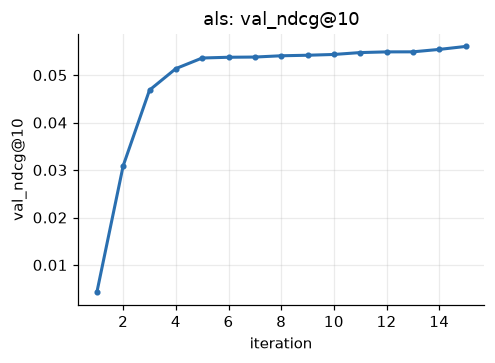

In [5]:
curve_plot("als")

In [6]:
rows = []
for run, label in (("als_final", "als: learned user vectors"), ("als_foldall", "als+history: user vectors computed from the history given")):
    r = json.load(open(RESULTS_DIR / f"{run}.json"))
    rows.append({"variant": label, "val_ndcg@10": r["val"]["ndcg@10"], "test_recall@10": r["test"]["recall@10"],
                 "test_ndcg@10": r["test"]["ndcg@10"], "test_mrr": r["test"]["mrr"]})
pd.DataFrame(rows).round(4)

,variant,val_ndcg@10,test_recall@10,test_ndcg@10,test_mrr
0,als: learned user vectors,0.0524,0.0598,0.0324,0.0292
1,als+history: user vectors computed from the hi...,0.0525,0.0785,0.0432,0.0385


Validation NDCG@10 by number of factors: 0.0400 at 32, 0.0449 at 64, 0.0494 at 128, 0.0524 at 256; fit times 16 s, 45 s, 134 s, 796 s. Doubling the factors costs about 5.9 times the training time for a smaller gain each time. Regularisation between 0.01 and 100 barely matters (validation NDCG@10 within 0.0006) and 1000 hurts (0.0210); confidence alpha = 10 is worse (0.0458) and 100 is no better than 40 (0.0493). The final run (256 factors) has test Recall@10 0.0598 and NDCG@10 0.0324. Its validation NDCG@10 (0.0524) is far above its test NDCG@10 because the learned user vectors never saw the validation purchase, which the test item is scored after. Computing each user's vector from the history the harness gives it (the same item factors, nothing retrained; the row called als+history) raises test NDCG@10 from 0.0324 to 0.0432 and Recall@10 from 0.0598 to 0.0785, closing 54% of the validation-to-test gap, so a large part of that gap is the evaluation protocol and not the model. This variant was added after noticing the gap, it has no tunable parameters, and it is reported next to plain ALS, not instead of it.

## svd
Biased matrix factorization for rating prediction: mu + user bias + item bias + user vector . item vector, trained with Adam on squared error. It is the model for the RMSE metric; for the ranking metrics it ranks items by predicted rating.

In [7]:
sw = sweep_table("svd", by='val_rmse')
print("svd: {} runs, winner on validation: {}".format(len(sw), sw.loc[sw["selected"], "run"].iloc[0]))
sw[["run"] + [c for c in sw.columns if c.startswith("cfg_")] + ["val_ndcg@10", "val_rmse", "test_recall@10", "fit_seconds", "selected"]].head(12)

svd: 24 runs, winner on validation: svd_final


,run,cfg_factors,cfg_lr,cfg_reg,cfg_epochs,cfg_patience,cfg_batch_size,val_ndcg@10,val_rmse,test_recall@10,fit_seconds,selected
0,svd_final,32,0.005,0.5,30,3,8192,0.000059,1.096752,0.000306,15.93,True
1,svd_factors32_reg0.5,32,0.005,0.5,30,3,8192,0.000059,1.096752,0.000306,17.68,False
2,svd_factors16_reg0.5,16,0.005,0.5,30,3,8192,0.000048,1.096959,0.000285,12.51,False
3,svd_factors64_reg0.5,64,0.005,0.5,30,3,8192,0.000059,1.096982,0.000232,23.85,False
4,svd_factors8_reg0.5,8,0.005,0.5,30,3,8192,0.000040,1.097001,0.000306,11.47,False
5,svd_factors64_reg0.2,64,0.005,0.2,30,3,8192,0.000132,1.102036,0.000306,26.56,False
6,svd_factors32_reg1.0,32,0.005,1.0,30,3,8192,0.000073,1.105356,0.000317,15.45,False
7,svd_factors16_reg1.0,16,0.005,1.0,30,3,8192,0.000073,1.105356,0.000317,11.65,False
8,svd_factors32_reg0.2,32,0.005,0.2,30,3,8192,0.000087,1.109012,0.000232,18.28,False
9,svd_factors64_reg0.1,64,0.005,0.1,30,3,8192,0.000200,1.113677,0.000317,23.60,False


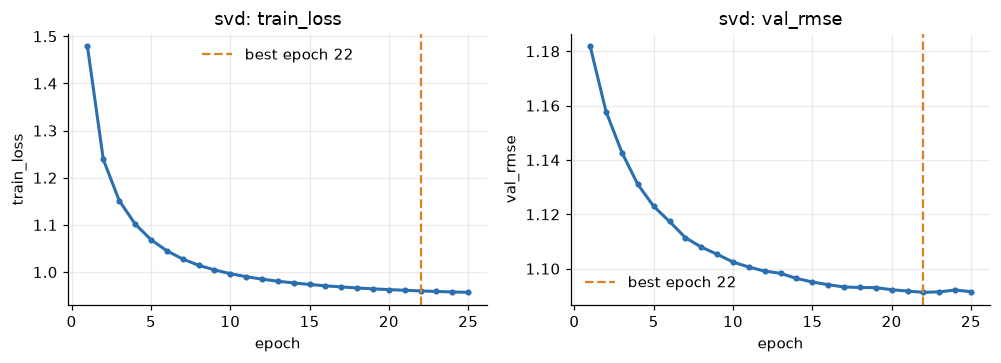

In [8]:
curve_plot("svd")

Validation RMSE falls from 1.1538 at reg 0.05 to 1.0968 at reg 0.5 and rises again beyond it; the number of factors hardly matters at that regularisation. Final test RMSE is 1.1785 (MAE 0.8334) against 1.2500 for the popularity baseline, an improvement of 5.7%. As a recommender it is no better than chance: Recall@10 is 0.0003 against 0.0004 for chance. Predicting a rating accurately and ranking the items a user will buy are different problems, and a model trained on rating error does not solve the second.

## bpr
Bayesian personalised ranking matrix factorization (Rendle et al., 2009). Trained directly to rank: an item the user interacted with should score above a sampled item they did not.

In [9]:
sw = sweep_table("bpr")
print("bpr: {} runs, winner on validation: {}".format(len(sw), sw.loc[sw["selected"], "run"].iloc[0]))
sw[["run"] + [c for c in sw.columns if c.startswith("cfg_")] + ["val_ndcg@10", "test_recall@10", "fit_seconds", "selected"]].head(12)

bpr: 17 runs, winner on validation: bpr_final


,run,cfg_factors,cfg_lr,cfg_reg,cfg_epochs,cfg_batch_size,cfg_patience,val_ndcg@10,test_recall@10,fit_seconds,selected
0,bpr_final,128,0.005,0.003,80,4096,15,0.039843,0.051951,174.30,True
1,bpr_patience15_epochs80_factors128_reg0.003,128,0.005,0.003,80,4096,15,0.039843,0.051951,168.87,True
2,bpr_r2_f128_reg0.001,128,0.005,0.001,150,4096,30,0.039786,0.051529,564.69,False
3,bpr_r2_f256,256,0.005,0.003,150,4096,15,0.037887,0.049102,265.90,False
4,bpr_patience15_epochs80_factors64_reg0.003,64,0.005,0.003,80,4096,15,0.035743,0.047625,112.54,False
5,bpr_patience15_epochs80_factors64_reg0.01,64,0.005,0.010,80,4096,15,0.033408,0.047065,94.54,False
6,bpr_patience15_epochs80_factors128_reg0.01,128,0.005,0.010,80,4096,15,0.033097,0.047435,70.38,False
7,bpr_factors64_reg0.003,64,0.005,0.003,50,4096,5,0.030940,0.042179,74.12,False
8,bpr_factors64_reg0.01,64,0.005,0.010,50,4096,5,0.030464,0.043256,38.45,False
9,bpr_r2_f128_lr0.01,128,0.010,0.003,150,4096,15,0.028904,0.040406,150.01,False


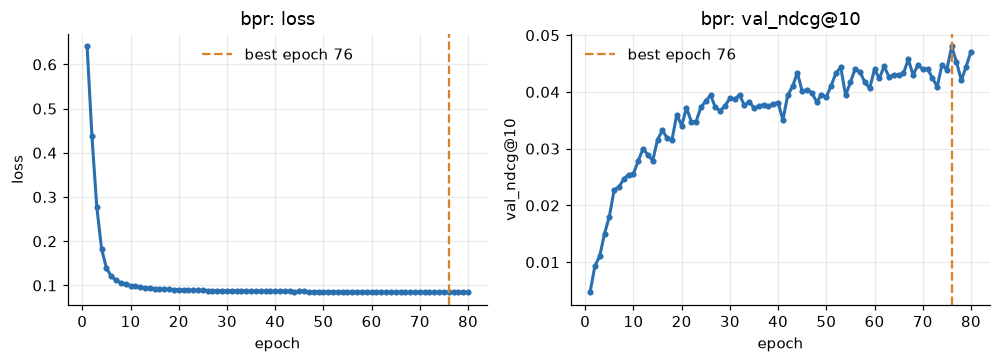

In [10]:
curve_plot("bpr")

BPR is sensitive to regularisation. With reg of 0.001 or less, training stopped at the popularity solution (validation NDCG@10 0.0169 against popularity's 0.0136); reg 0.003 to 0.01 learned real preferences (0.0309 and 0.0305); longer patience and 128 factors raised it to 0.0398. The final run has test Recall@10 0.0520 and NDCG@10 0.0271 after 76 of 80 epochs, fitting in 174 s. Its best epoch is at the 80-epoch cap, so it was still improving; a 150-epoch run with weaker regularisation reached the same validation score (0.0398), so BPR looks close to its ceiling on this data but may be slightly undertrained.

## content
Content-based hybrid. Every item's text (title, features, description) is embedded with a frozen sentence-transformers encoder (all-MiniLM-L6-v2); a user's profile is the mean embedding of their history, plus a mild popularity prior. It can recommend items nobody has bought yet.

In [11]:
sw = sweep_table("content")
print("content: {} runs, winner on validation: {}".format(len(sw), sw.loc[sw["selected"], "run"].iloc[0]))
sw[["run"] + [c for c in sw.columns if c.startswith("cfg_")] + ["val_ndcg@10", "test_recall@10", "fit_seconds", "selected"]].head(12)

content: 13 runs, winner on validation: content_final


,run,cfg_lam,val_ndcg@10,test_recall@10,fit_seconds,selected
0,content_final,0.50,0.022477,0.038212,0.01,True
1,content_lam0.5,0.50,0.022477,0.038212,0.01,True
2,content_lam0.7,0.70,0.022390,0.038697,0.01,False
3,content_lam1.0,1.00,0.021271,0.037230,0.01,False
4,content_lam0.3,0.30,0.020825,0.035246,0.00,False
5,content_lam1.4,1.40,0.019558,0.034465,0.00,False
6,content_lam2,2.00,0.017642,0.031563,0.00,False
7,content_lam3,3.00,0.016380,0.028957,0.00,False
8,content_lam5,5.00,0.015651,0.027363,0.00,False
9,content_first,0.10,0.015144,0.025189,136.32,False


Text similarity alone (lam = 0) reaches test Recall@10 0.0183, 73% of popularity's, with no interaction data about the items. Adding a popularity prior helps up to lam = 0.5 (validation NDCG@10 0.0225); beyond that the model drifts back toward plain popularity. The final run has test Recall@10 0.0382 and NDCG@10 0.0199. The encoder is frozen, so nothing is trained and the run takes 0.01 s once the embeddings are cached.

## Final runs against the popularity baseline

In [12]:

rows = []
for name in ["popularity"] + ['knn', 'als', 'svd', 'bpr', 'content']:
    r = json.load(open(RESULTS_DIR / f"{name}_final.json"))
    t, c = r["test"], r["cost"]
    rows.append({"model": name, "recall@10": t["recall@10"], "ndcg@10": t["ndcg@10"], "mrr": t["mrr"], "rmse": t["rmse"],
                 "coverage@10": t["coverage@10"], "fit_seconds": c["fit_seconds"], "score_ms_per_user": c["score_ms_per_user"]})
pd.DataFrame(rows).round(4)


,model,recall@10,ndcg@10,mrr,rmse,coverage@10,fit_seconds,score_ms_per_user
0,popularity,0.0249,0.0126,0.0120,1.2500,0.0008,0.00,0.0013
1,knn,0.0562,0.0312,0.0284,NaN,0.9648,0.32,0.0482
2,als,0.0598,0.0324,0.0292,NaN,0.2693,795.93,0.0075
3,svd,0.0003,0.0002,0.0003,1.1785,0.0118,15.93,0.0077
4,bpr,0.0520,0.0271,0.0252,NaN,0.3875,174.30,0.0076
5,content,0.0382,0.0199,0.0188,NaN,0.2525,0.01,0.0169
